# Exploratory overview — `2015.csv` (BRFSS 2015)

This file is the CDC **Behavioral Risk Factor Surveillance System** 2015 survey: one row per respondent, one column per question or derived variable.

**Goal:** get a general feel for the data — size, types, missing values, and the distribution of a handful of key health variables.

> ⚠️ BRFSS uses **special codes** instead of NaN: `7`/`77`/`777` = *don't know*, `9`/`99`/`999` = *refused*, and `88` = *none* (e.g. 0 days). We decode these before plotting.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
# Colour palette (colour-blind-checked categorical order)
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
BLUE = PALETTE[0]
sns.set_theme(style='whitegrid', palette=PALETTE)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False,
                     'grid.color': '#e6e6e3', 'axes.edgecolor': '#999'})

## 1. Load the data
The file is ~500 MB, so loading takes a little while.

In [2]:
df = pd.read_csv('2015.csv')
print(f'{df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'Memory: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB')

441,456 rows × 330 columns
Memory: 1.18 GB


In [3]:
df.head()

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENUM,PVTRESD1,COLGHOUS,STATERES,CELLFON3,LADULT,NUMADULT,NUMMEN,NUMWOMEN,CTELNUM1,CELLFON2,CADULT,PVTRESD2,CCLGHOUS,CSTATE,LANDLINE,...,_MINAC21,STRFREQ_,PAMISS1_,PAMIN11_,PAMIN21_,PA1MIN_,PAVIG11_,PAVIG21_,PA1VIGM_,_PACAT1,_PAINDX1,_PA150R2,_PA300R2,_PA30021,_PASTRNG,_PAREC1,_PASTAE1,_LMTACT1,_LMTWRK1,_LMTSCL1,_RFSEAT2,_RFSEAT3,_FLSHOT6,_PNEUMO2,_AIDTST3
0,1.0,1.0,b'01292015',b'01',b'29',b'2015',1200.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,3.0,1.000000e+00,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,5.397605e-79,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,1.0
1,1.0,1.0,b'01202015',b'01',b'20',b'2015',1100.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,1.0,5.397605e-79,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,5.397605e-79,5.397605e-79,5.397605e-79,168.0,5.397605e-79,168.0,5.397605e-79,5.397605e-79,5.397605e-79,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,3.0,3.0,4.0,2.0,2.0,NaN,NaN,2.0
2,1.0,1.0,b'02012015',b'02',b'01',b'2015',1200.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,2.0,1.000000e+00,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,9.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,NaN
3,1.0,1.0,b'01142015',b'01',b'14',b'2015',1100.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,3.0,1.000000e+00,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,5.397605e-79,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,9.0
4,1.0,1.0,b'01142015',b'01',b'14',b'2015',1100.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,2.0,1.000000e+00,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,5.397605e-79,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,1.0


## 2. Column types
Almost everything is numeric (answers are stored as codes). The few text columns are dates stored as byte strings like `b'01292015'`.

In [4]:
print(df.dtypes.value_counts())
print('\nNon-numeric columns:', df.select_dtypes(exclude='number').columns.tolist())

float64    323
str          7
Name: count, dtype: int64

Non-numeric columns: ['IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'PCDMDECN', 'EXACTOT1', 'EXACTOT2']


In [5]:
# Clean the byte-string date into a real date
df['IDATE'] = pd.to_datetime(df['IDATE'].str.strip("b'"), format='%m%d%Y', errors='coerce')
df['IDATE'].describe()

count                        441456
mean     2015-07-06 11:40:19.441122
min             2015-01-02 00:00:00
25%             2015-04-02 00:00:00
50%             2015-07-07 00:00:00
75%             2015-10-13 00:00:00
max             2016-03-08 00:00:00
Name: IDATE, dtype: object

## 3. Missing values
With 330 columns, many questions were only asked in some states or to some respondents (optional modules), so missingness is high for a lot of columns.

In [6]:
missing = df.isna().mean().sort_values(ascending=False)
print(f'Overall missing cells: {df.isna().mean().mean():.1%}')
print(f'Columns with no missing values: {(missing == 0).sum()}')
print(f'Columns more than 50% missing: {(missing > 0.5).sum()}')
print(f'Columns more than 90% missing: {(missing > 0.9).sum()}')

Overall missing cells: 44.5%
Columns with no missing values: 86
Columns more than 50% missing: 150
Columns more than 90% missing: 102


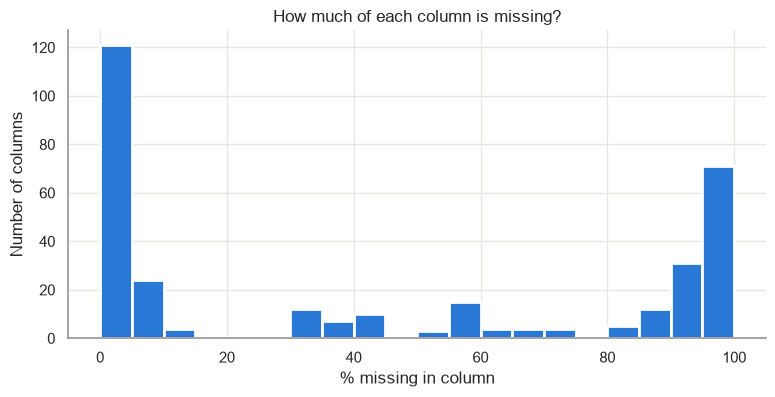

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(missing * 100, bins=20, color=BLUE, edgecolor='white', linewidth=2)
ax.set(title='How much of each column is missing?', xlabel='% missing in column', ylabel='Number of columns')
plt.show()

In [8]:
missing.head(15).to_frame('fraction_missing')

,fraction_missing
QLSTRES2,1.000000
PAINACT2,1.000000
QLHLTH2,1.000000
QLMENTL2,1.000000
LADULT,0.999898
COLGHOUS,0.999898
ASDRVIST,0.999293
ASERVIST,0.999291
ASNOSLEP,0.998965
ASTHMED3,0.998553


## 4. A focused subset of key variables
330 columns is too many to look at one by one. Here are 14 widely used ones. Their meanings come from the BRFSS 2015 codebook:

| Column | Meaning |
|---|---|
| `GENHLTH` | General health (1 = Excellent … 5 = Poor) |
| `PHYSHLTH` / `MENTHLTH` | Days of poor physical / mental health in the past 30 days |
| `_BMI5` | Body mass index × 100 |
| `SEX` | 1 = Male, 2 = Female |
| `_AGEG5YR` | Age in 5-year groups (1 = 18–24 … 13 = 80+) |
| `_EDUCAG`, `_INCOMG` | Education level, income group |
| `_SMOKER3` | Smoking status |
| `DIABETE3`, `_RFHYPE5`, `CVDINFR4` | Diabetes, high blood pressure, heart attack ever |
| `EXERANY2` | Any exercise in the past month |
| `_STATE` | State FIPS code |

In [9]:
cols = ['_STATE', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', '_BMI5', 'SEX', '_AGEG5YR', '_EDUCAG',
        '_INCOMG', '_SMOKER3', 'DIABETE3', '_RFHYPE5', 'CVDINFR4', 'EXERANY2']
d = df[cols].copy()

# --- Decode the special codes ---
for c in ['GENHLTH', 'DIABETE3', 'CVDINFR4', 'EXERANY2']:
    d[c] = d[c].replace({7: np.nan, 9: np.nan})
for c in ['PHYSHLTH', 'MENTHLTH']:
    d[c] = d[c].replace({88: 0, 77: np.nan, 99: np.nan})
d['_AGEG5YR'] = d['_AGEG5YR'].replace({14: np.nan})
for c in ['_EDUCAG', '_INCOMG', '_SMOKER3', '_RFHYPE5']:
    d[c] = d[c].replace({9: np.nan})
d['BMI'] = d.pop('_BMI5') / 100

# --- Readable labels ---
d['SEX'] = d['SEX'].map({1: 'Male', 2: 'Female'})
d['GENHLTH'] = d['GENHLTH'].map({1: 'Excellent', 2: 'Very good', 3: 'Good', 4: 'Fair', 5: 'Poor'})
d['DIABETE3'] = d['DIABETE3'].map({1: 'Yes', 2: 'Yes (pregnancy only)', 3: 'No', 4: 'Pre-diabetes'})
d['_SMOKER3'] = d['_SMOKER3'].map({1: 'Daily smoker', 2: 'Some days', 3: 'Former smoker', 4: 'Never smoked'})
d['_RFHYPE5'] = d['_RFHYPE5'].map({1: 'No', 2: 'Yes'})   # 2 = has high blood pressure
d['CVDINFR4'] = d['CVDINFR4'].map({1: 'Yes', 2: 'No'})
d['EXERANY2'] = d['EXERANY2'].map({1: 'Yes', 2: 'No'})
age_labels = ['18-24','25-29','30-34','35-39','40-44','45-49','50-54','55-59','60-64','65-69','70-74','75-79','80+']
d['AGE'] = pd.Categorical(d.pop('_AGEG5YR').map(dict(enumerate(age_labels, 1))), categories=age_labels, ordered=True)
d.head()

,_STATE,GENHLTH,PHYSHLTH,MENTHLTH,SEX,_EDUCAG,_INCOMG,_SMOKER3,DIABETE3,_RFHYPE5,CVDINFR4,EXERANY2,BMI,AGE
0,1.0,Poor,15.0,18.0,Female,2.0,2.0,Former smoker,No,Yes,No,No,40.18,60-64
1,1.0,Good,0.0,0.0,Female,4.0,1.0,Daily smoker,No,No,No,Yes,25.09,50-54
2,1.0,Fair,15.0,0.0,Female,2.0,NaN,NaN,No,No,NaN,NaN,22.04,70-74
3,1.0,Poor,30.0,30.0,Female,2.0,5.0,Never smoked,No,Yes,No,No,28.19,60-64
4,1.0,Poor,20.0,0.0,Female,3.0,NaN,Never smoked,No,No,No,No,24.37,60-64


### 4.1 Numeric summary

In [10]:
d[['BMI', 'PHYSHLTH', 'MENTHLTH']].describe().round(2)

,BMI,PHYSHLTH,MENTHLTH
count,405058.00,431713.00,434048.00
mean,28.04,4.30,3.32
std,6.65,8.82,7.62
min,12.02,0.00,0.00
25%,23.73,0.00,0.00
50%,26.95,0.00,0.00
75%,30.90,3.00,2.00
max,99.95,30.00,30.00


### 4.2 Distributions of numeric variables

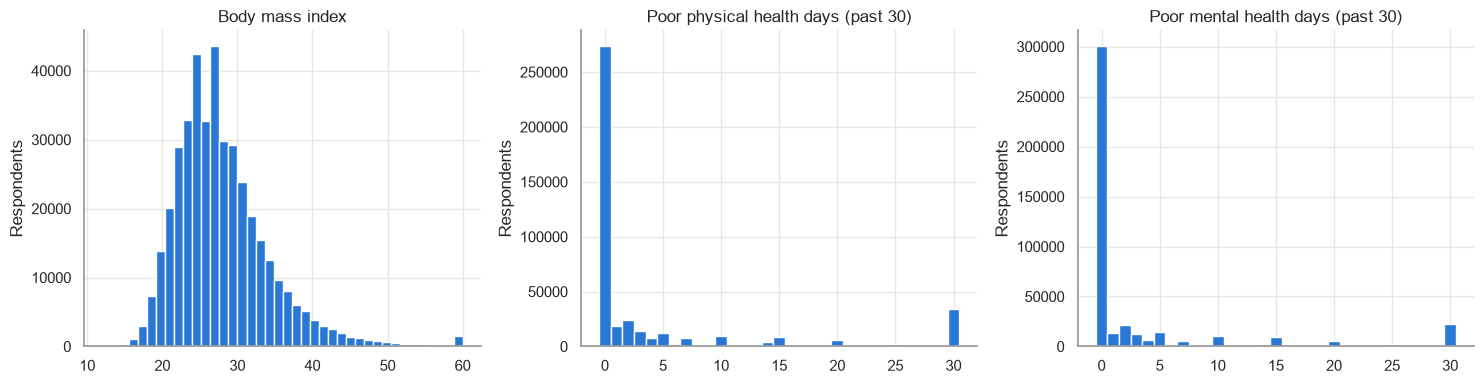

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
specs = [('BMI', 'Body mass index', (12, 60)),
         ('PHYSHLTH', 'Poor physical health days (past 30)', (0, 30)), ('MENTHLTH', 'Poor mental health days (past 30)', (0, 30))]
for ax, (c, title, rng) in zip(axes.flat, specs):
    bins = 40 if c == 'BMI' else np.arange(rng[0], rng[1] + 2) - 0.5
    ax.hist(d[c].dropna().clip(*rng), bins=bins, color=BLUE, edgecolor='white', linewidth=1)
    ax.set(title=title, ylabel='Respondents')
plt.tight_layout(); plt.show()

**What to notice:** most people report **0** bad health days, with a spike at **30** (chronic issues). BMI is right-skewed and centred around 27, which is the 'overweight' range.

### 4.3 Categorical variables

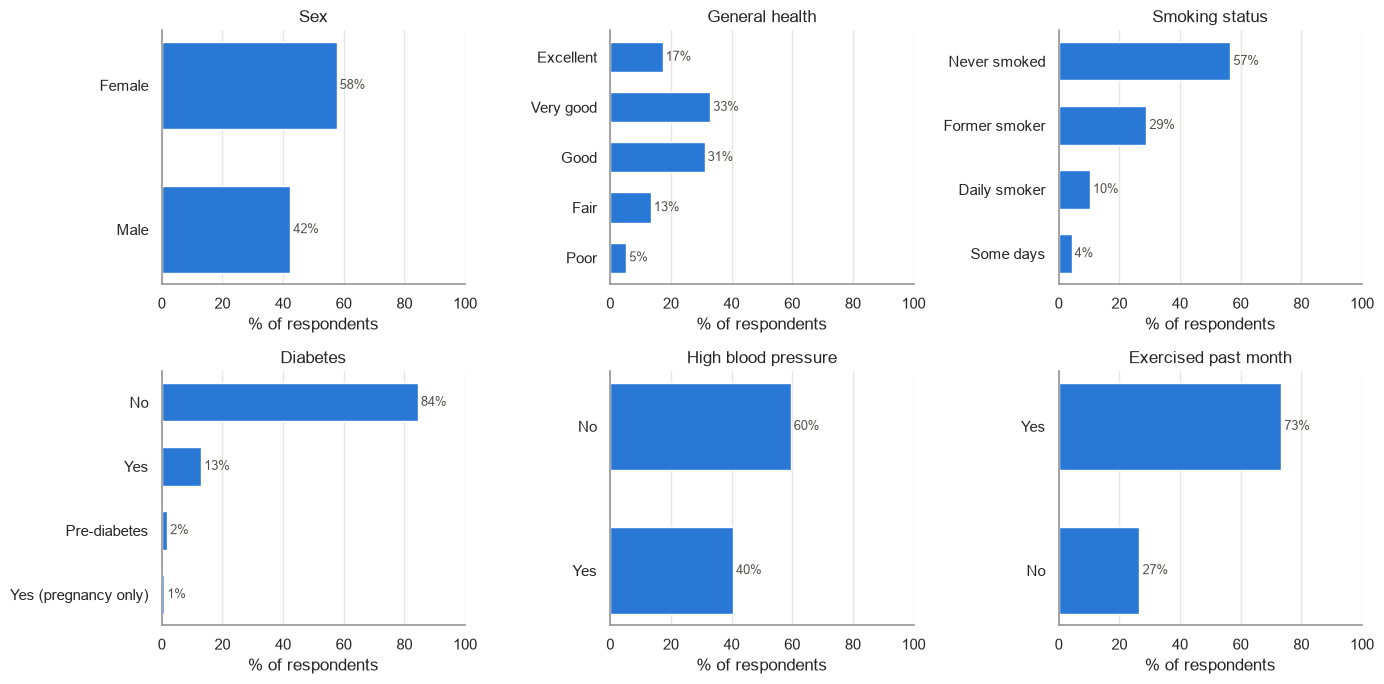

In [12]:
cat_cols = ['SEX', 'GENHLTH', '_SMOKER3', 'DIABETE3', '_RFHYPE5', 'EXERANY2']
titles = ['Sex', 'General health', 'Smoking status', 'Diabetes', 'High blood pressure', 'Exercised past month']
order = {'GENHLTH': ['Excellent', 'Very good', 'Good', 'Fair', 'Poor']}
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c, t in zip(axes.flat, cat_cols, titles):
    vc = d[c].value_counts(normalize=True) * 100
    if c in order: vc = vc.reindex(order[c])
    ax.barh(vc.index[::-1], vc.values[::-1], color=BLUE, height=0.6)
    for y, v in enumerate(vc.values[::-1]):
        ax.text(v + 1, y, f'{v:.0f}%', va='center', fontsize=9, color='#52514e')
    ax.set(title=t, xlim=(0, 100)); ax.set_xlabel('% of respondents')
    ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

### 4.4 Who answered? Age distribution

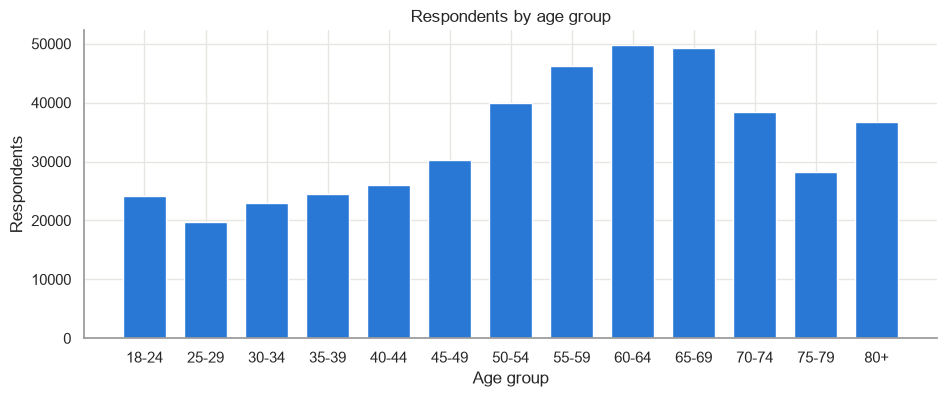

In [13]:
fig, ax = plt.subplots(figsize=(11, 4))
vc = d['AGE'].value_counts().sort_index()
ax.bar(vc.index.astype(str), vc.values, color=BLUE, width=0.7)
ax.set(title='Respondents by age group', xlabel='Age group', ylabel='Respondents')
plt.show()

The survey leans older: there are more respondents aged 50–74 than young adults. Keep this in mind, because raw averages over-represent older people. BRFSS provides the weight column `_LLCPWT` to correct for that.

## 5. Relationships between variables

### 5.1 Correlation between numeric/ordinal variables

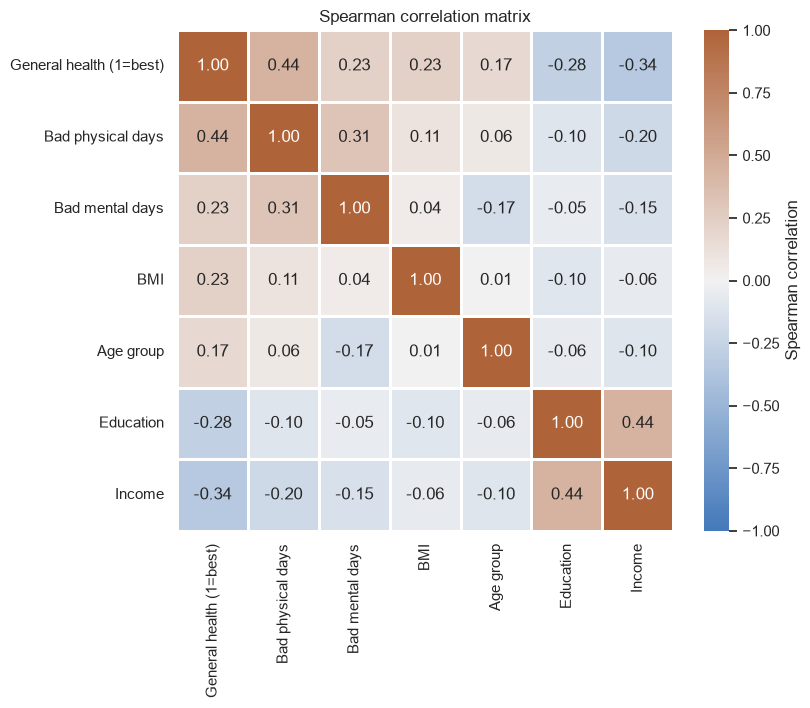

In [14]:
num = df[cols].copy()
num['GENHLTH'] = num['GENHLTH'].replace({7: np.nan, 9: np.nan})
for c in ['PHYSHLTH', 'MENTHLTH']: num[c] = num[c].replace({88: 0, 77: np.nan, 99: np.nan})
num['_AGEG5YR'] = num['_AGEG5YR'].replace({14: np.nan})
for c in ['_EDUCAG', '_INCOMG']: num[c] = num[c].replace({9: np.nan})
num['BMI'] = num.pop('_BMI5') / 100
num = num[['GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'BMI', '_AGEG5YR', '_EDUCAG', '_INCOMG']]
num.columns = ['General health (1=best)', 'Bad physical days', 'Bad mental days', 'BMI', 'Age group', 'Education', 'Income']

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(num.corr(method='spearman'), annot=True, fmt='.2f', cmap=sns.diverging_palette(250, 30, as_cmap=True),
            vmin=-1, vmax=1, center=0, linewidths=2, linecolor='white', cbar_kws={'label': 'Spearman correlation'}, ax=ax)
ax.set_title('Spearman correlation matrix')
plt.show()

Higher `GENHLTH` means *worse* health, so its positive correlation with bad-health days makes sense. Its negative correlation with income and education means that richer and more educated respondents tend to report better health.

### 5.2 Self-rated health by income group

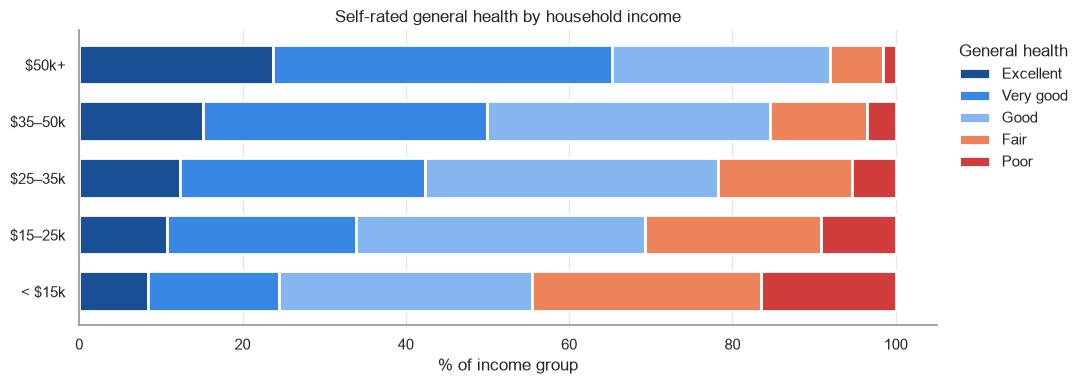

In [15]:
inc_labels = {1: '< $15k', 2: '$15–25k', 3: '$25–35k', 4: '$35–50k', 5: '$50k+'}
tmp = pd.DataFrame({'Income': df['_INCOMG'].map(inc_labels), 'Health': d['GENHLTH']}).dropna()
ct = pd.crosstab(tmp['Income'], tmp['Health'], normalize='index').reindex(list(inc_labels.values()))[order['GENHLTH']] * 100
seq = ['#184f95', '#3987e5', '#86b6ef', '#ec835a', '#d03b3b']  # good (blue) → poor (red)
ax = ct.plot(kind='barh', stacked=True, figsize=(11, 4), color=seq, width=0.7, edgecolor='white', linewidth=2)
ax.set(title='Self-rated general health by household income', xlabel='% of income group', ylabel='')
ax.legend(title='General health', bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)
ax.grid(axis='y', visible=False); plt.tight_layout(); plt.show()

### 5.3 BMI and chronic conditions

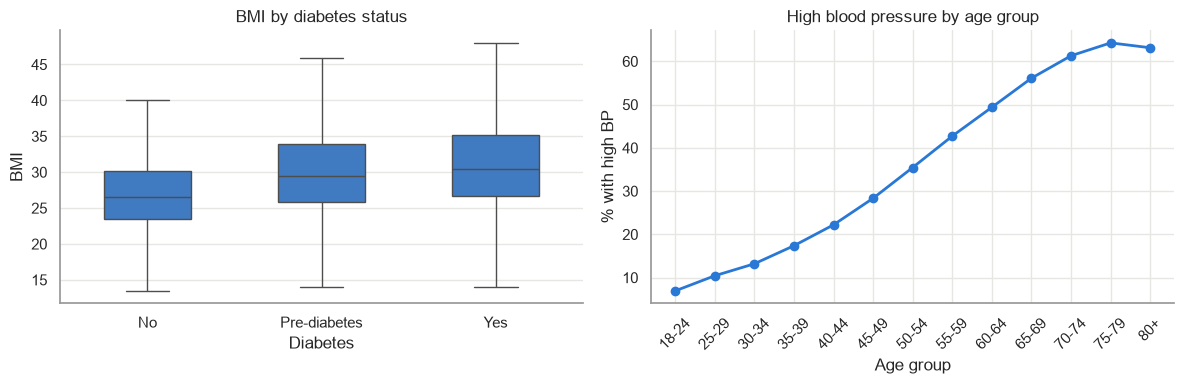

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sub = d[d['DIABETE3'].isin(['Yes', 'No', 'Pre-diabetes'])]
sns.boxplot(data=sub, x='DIABETE3', y='BMI', order=['No', 'Pre-diabetes', 'Yes'], color=BLUE, showfliers=False, width=0.5, ax=axes[0])
axes[0].set(title='BMI by diabetes status', xlabel='Diabetes', ylabel='BMI')
rate = d.groupby('AGE', observed=True)['_RFHYPE5'].apply(lambda s: (s == 'Yes').mean() * 100)
axes[1].plot(rate.index.astype(str), rate.values, color=BLUE, lw=2, marker='o', ms=6)
axes[1].set(title='High blood pressure by age group', xlabel='Age group', ylabel='% with high BP')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

### 5.4 Respondents per state

53 states/territories; median 6,943 respondents each


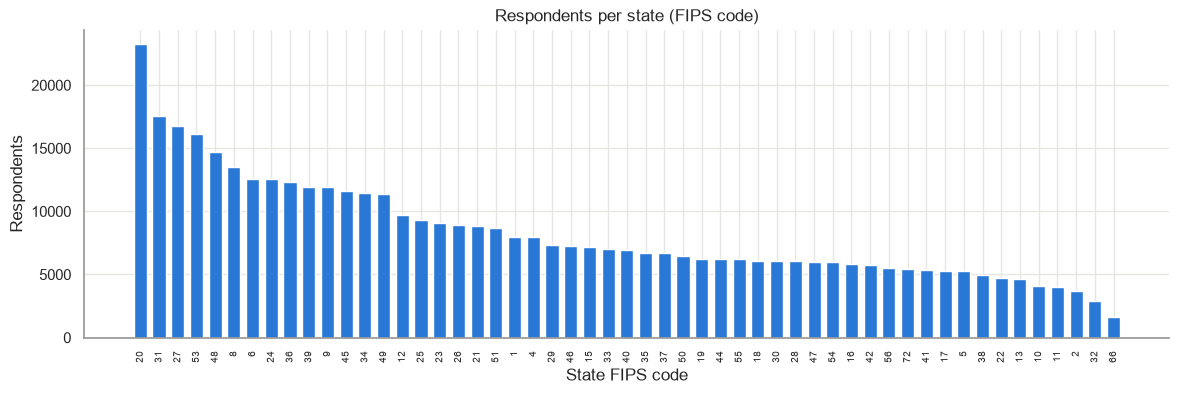

In [17]:
state_counts = df['_STATE'].value_counts()
print(f'{state_counts.size} states/territories; median {state_counts.median():,.0f} respondents each')
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(state_counts.index.astype(int).astype(str), state_counts.values, color=BLUE, width=0.7)
ax.set(title='Respondents per state (FIPS code)', xlabel='State FIPS code', ylabel='Respondents')
ax.tick_params(axis='x', rotation=90, labelsize=7); plt.show()

## 6. Takeaways
- **Large and wide:** about 441k respondents × 330 variables. Most columns are numeric codes, so you need the [BRFSS 2015 codebook](https://www.cdc.gov/brfss/annual_data/annual_2015.html) to read them.
- **Special codes matter:** values like 7/9/77/88/99 must be recoded before analysis, or means and correlations will be wrong.
- **Lots of structural missingness:** many columns come from optional modules and are more than 90% empty. Pick a subset of columns that suits your question.
- **Clear patterns already visible:** health worsens with age, lower income and higher BMI, and bad-health days are bimodal (0 or 30).
- **Survey weights:** the sample is skewed toward older adults. Use `_LLCPWT` if you need population-level estimates.

**Possible next steps:** choose a target (e.g. `DIABETE3` or `CVDINFR4`) for a classification model, then select and clean the relevant features.

## 7. Quick check: empty values, cleaning, and relations between columns
This section **only reads** the data. Nothing in `df` or in the CSV file is modified.

### 7.1 How many empty values?

In [18]:
raw = pd.read_csv('2015.csv')   # fresh, untouched copy
total_cells = raw.size
empty_cells = raw.isna().sum().sum()
print(f'Total cells          : {total_cells:,}')
print(f'Empty (NaN) cells    : {empty_cells:,}  ({empty_cells / total_cells:.1%})')
print(f'Rows with no empty   : {(~raw.isna().any(axis=1)).sum():,} of {len(raw):,}')
print(f'Duplicate rows       : {raw.duplicated().sum():,}')

# Empty values per column, sorted (the 20 emptiest)
raw.isna().sum().sort_values(ascending=False).head(20).to_frame('empty_values')

Total cells          : 145,680,480
Empty (NaN) cells    : 64,809,261  (44.5%)
Rows with no empty   : 0 of 441,456
Duplicate rows       : 0


,empty_values
QLSTRES2,441456
PAINACT2,441456
QLHLTH2,441456
QLMENTL2,441456
LADULT,441411
COLGHOUS,441411
ASDRVIST,441144
ASERVIST,441143
ASNOSLEP,440999
ASTHMED3,440817


### 7.2 Hidden missing values (special codes)
Some answers are not NaN, but they mean *don't know* or *refused* (7/9, 77/99). They look like real numbers, so you need to recode them as well.

In [19]:
hidden = {c: raw[c].isin([7, 9]).sum() for c in ['GENHLTH', 'DIABETE3', 'CVDINFR4', 'EXERANY2', '_SMOKER3', '_RFHYPE5', '_INCOMG', '_EDUCAG']}
hidden.update({c: raw[c].isin([77, 99]).sum() for c in ['PHYSHLTH', 'MENTHLTH']})
pd.Series(hidden, name='hidden_missing (coded 7/9/77/99)').to_frame()

,hidden_missing (coded 7/9/77/99)
GENHLTH,1245
DIABETE3,791
CVDINFR4,2229
EXERANY2,2548
_SMOKER3,17990
_RFHYPE5,1367
_INCOMG,79505
_EDUCAG,1811
PHYSHLTH,9742
MENTHLTH,7408


### 7.3 Do I need to clean it?
**Yes.** Here is why:
- **About 45% of all cells are empty**, and **no row is complete**, so you can't just call `dropna()`, because it would delete every row. Instead, drop the columns that are mostly empty (many are more than 90% empty) and keep the ones relevant to your question.
- **Special codes** (7, 9, 77, 99, 88) must be recoded, or they will distort averages and models. For example, `_INCOMG` has about 80k "don't know/refused" answers coded as 9.
- **Dates** are stored as byte strings (`b'01292015'`).
- Good news: there are **no duplicate rows**.

### 7.4 Is there a relation between the columns?
This computes the Spearman correlation between every pair of numeric columns that is less than 50% empty. It uses a 50k-row sample to keep it fast.

In [20]:
num = raw.select_dtypes('number')
num = num.loc[:, (num.isna().mean() < 0.5) & (num.nunique() > 1)]
corr = num.sample(50_000, random_state=0).corr(method='spearman').abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)

print(f'Columns compared        : {num.shape[1]}')
print(f'Pairs compared          : {len(pairs):,}')
print(f'Very strong (|r| > 0.9) : {(pairs > 0.9).sum()}')
print(f'Moderate+  (|r| > 0.5)  : {(pairs > 0.5).sum()}')
pairs.head(20).rename('abs_spearman').to_frame()

Columns compared        : 171
Pairs compared          : 29,241
Very strong (|r| > 0.9) : 66
Moderate+  (|r| > 0.5)  : 304


,,abs_spearman
SEQNO,_PSU,1.000000
HTIN4,HTM4,1.000000
EXERHMM1,PADUR1_,1.000000
HAVARTH3,_DRDXAR1,1.000000
HEIGHT3,HTIN4,1.000000
EXERANY2,_TOTINDA,1.000000
MAXVO2_,FC60_,0.999998
HIVTST6,_AIDTST3,0.999982
_RACE,_RACEGR3,0.999937
EDUCA,_EDUCAG,0.999825


**Reading the result:**
- **Yes, there are relations, but most strong ones are duplicates.** BRFSS stores the raw answer *and* a derived version of it, for example `HEIGHT3` ↔ `HTIN4` ↔ `HTM4` (height in different units), `EDUCA` ↔ `_EDUCAG`, and `EXERANY2` ↔ `_TOTINDA`. These pairs carry the same information, so **keep only one of each** for modelling.
- **The meaningful health relations are moderate.** See section 5.1: general health goes with bad physical days (r ≈ 0.44), and with income (≈ −0.34) and education (≈ −0.28). Health also gets worse with age and BMI.
- Most of the roughly 29k column pairs show little or no correlation.